# ACML Assignment 2: Convolutional Autoencoders

**Authors:** Simon Delecluse, Francesco Suriano

## Abstract
In this work we build a convolutional autoencoder in PyTorch and use it first to reconstruct CIFAR-10 images and then to colourise grayscale ones.

We start from the architecture given in the assignment: an encoder with three convolutions and two max pooling layers squeezes the 32x32x3 image into an 8x8x16 latent code, and a decoder with upsampling and convolutions rebuilds it. This small model already keeps the shapes and the main colours of the images, but the reconstructions are blurry and the fine details get lost in the bottleneck.

Then we try three other types of autoencoder, each with three latent sizes (512, 1024 and 2048 values): a wider version of the baseline, versions with one and three conv + pool stages, and a two path encoder that looks at the image with small and big filters at the same time. A bigger latent always helps, but how the latent is built matters as much as its size. A latent with a very low resolution stays blurry even with many channels, while a high resolution latent gives good reconstructions with a tiny network. More capacity also helps, and the two path model with the bigger latent gives the sharpest images of all.

Finally we take this best model and use it for colourisation. We freeze its decoder and train a new encoder that reads the gray image, and then we let the whole network train. Both models add some colour compared to the plain gray image, but the colours stay pale and brownish, because the MSE loss pushes the network towards the average colour when it isn't sure what colour an object is. As a last try we predict only the colour part of the image (the U and V channels) and put it back together with the real gray image. This gives the best colourisation, and the images are as sharp as the input, since the details don't have to pass through the latent space anymore, even if the colours are still quite washed out.

## Imports and hyperparameters
Here we import only the libraries that we use in the notebook.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, TensorDataset

We set the seed for reproducibility and the hyperparameters of the training. We use the GPU for speed and we save every trained model in `results_report` so we don't have to train it again.

In [2]:
SEED = 456
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128
LR = 2e-3
EPOCHS = 30      # max epochs, early stopping usually ends sooner
PATIENCE = 5     # stop after 5 epochs without improvement on validation

# trained models are saved here, so running the notebook again doesn't retrain them
RESULTS_DIR = "results_report"
os.makedirs(RESULTS_DIR, exist_ok=True)

torch.manual_seed(SEED)
print(DEVICE)

cuda


## Data
CIFAR-10 has 60 000 colour images of 32x32x3. We merge the official train and test sets, shuffle them and split them again **80 / 10 / 10** (48k train, 6k validation, 6k test). We need a validation set for the model checking while training, while the test set is used only to report the final error.

We scale the pixels from [0, 255] to **[0, 1]**, the same range as the sigmoid at the end of the decoder. Since it's an autoencoder, the target of every image is the image itself.

In [3]:
train_set = torchvision.datasets.CIFAR10(root="./data", train=True, download=True)
test_set = torchvision.datasets.CIFAR10(root="./data", train=False, download=True)

# (N, H, W, C) uint8 -> (N, C, H, W) float in [0, 1]
x = np.concatenate([train_set.data, test_set.data])
x = torch.from_numpy(x).permute(0, 3, 1, 2).float() / 255

# shuffle and split 80 / 10 / 10
x = x[torch.randperm(len(x), generator=torch.Generator().manual_seed(SEED))]
n_train, n_val = int(0.8 * len(x)), int(0.1 * len(x))
x_train, x_val, x_test = x[:n_train], x[n_train:n_train + n_val], x[n_train + n_val:]


def make_loader(inputs, targets, shuffle=False):
    return DataLoader(TensorDataset(inputs, targets), batch_size=BATCH_SIZE, shuffle=shuffle)


# for an autoencoder the target is the input itself
train_loader = make_loader(x_train, x_train, shuffle=True)
val_loader = make_loader(x_val, x_val)
test_loader = make_loader(x_test, x_test)

print("train", tuple(x_train.shape), "| val", tuple(x_val.shape), "| test", tuple(x_test.shape))

train (48000, 3, 32, 32) | val (6000, 3, 32, 32) | test (6000, 3, 32, 32)


## Helpers
Here we define the functions that will be useful later in the notebook:
- `evaluate` computes the average MSE of a model over a loader.
- `train` trains the model with **Adam** and the **MSE** loss. After every epoch we compute the validation loss, and if it doesn't improve for `PATIENCE` epochs we stop and go back to the weights of the best epoch (**early stopping**). Frozen layers are left out of the optimizer.
- `train_or_load` saves every trained model, so when we run the notebook again we just load it instead of training it again.
- `predict`, `count_params` and `latent_size` are utilities, while `plot_history` and `show_images` make the learning curves and the image grids.

In [4]:
loss_fn = nn.MSELoss()


def evaluate(model, loader):
    """average MSE over a loader"""
    model.eval()
    total = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            total += loss_fn(model(xb), yb).item() * len(xb)
    return total / len(loader.dataset)


def train(model, train_loader, val_loader, lr=LR):
    """Adam + MSE with early stopping, returns the train and val loss of every epoch"""
    params = [p for p in model.parameters() if p.requires_grad]   # frozen layers are left out
    optimizer = torch.optim.Adam(params, lr=lr)
    history = {"train": [], "val": []}
    best_val, best_weights, bad_epochs = float("inf"), None, 0

    for epoch in range(EPOCHS):
        model.train()
        total = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)

        history["train"].append(total / len(train_loader.dataset))
        history["val"].append(evaluate(model, val_loader))
        print(f"epoch {epoch + 1:2d}  train {history['train'][-1]:.5f}  val {history['val'][-1]:.5f}")

        if history["val"][-1] < best_val:
            best_val, bad_epochs = history["val"][-1], 0
            best_weights = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs == PATIENCE:
                print("early stopping")
                break

    model.load_state_dict(best_weights)
    return history


def train_or_load(name, model, train_loader, val_loader, lr=LR):
    """train the model and save it, or load it if it is already saved"""
    path = os.path.join(RESULTS_DIR, name.replace(" ", "_") + ".pt")
    model.to(DEVICE)
    if os.path.exists(path):
        saved = torch.load(path, map_location=DEVICE)
        model.load_state_dict(saved["weights"])
        print("loaded", path)
        return saved["history"]
    history = train(model, train_loader, val_loader, lr)
    torch.save({"weights": model.state_dict(), "history": history}, path)
    return history


def predict(model, x):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(xb.to(DEVICE)).cpu() for xb in x.split(500)])


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def latent_size(model, in_ch=3):
    """number of values in the latent code of one image"""
    dummy = torch.zeros(1, in_ch, 32, 32, device=next(model.parameters()).device)
    with torch.no_grad():
        return model.encoder(dummy).numel()


def plot_history(history, title):
    epochs = range(1, len(history["train"]) + 1)
    plt.figure(figsize=(6, 3.5))
    plt.plot(epochs, history["train"], label="train")
    plt.plot(epochs, history["val"], label="validation")
    plt.xlabel("epoch")
    plt.ylabel("MSE")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()


def show_images(rows, n=8, title=""):
    """rows: {label: images}, one row of n images per label (gray or RGB)"""
    fig, axes = plt.subplots(len(rows), n, figsize=(1.5 * n, 1.6 * len(rows)))
    for r, (label, images) in enumerate(rows.items()):
        for i in range(n):
            img = images[i].clamp(0, 1)
            if img.shape[0] == 1:
                axes[r, i].imshow(img[0], cmap="gray", vmin=0, vmax=1)
            else:
                axes[r, i].imshow(img.permute(1, 2, 0))
            axes[r, i].axis("off")
        axes[r, 0].set_title(label, loc="left", fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## Baseline autoencoder
We built the asked architecture, where every conv is 3x3 with stride 1, "same" padding and ReLU:

`Conv (8) -> MaxPool 2x2 -> Conv (12) -> MaxPool 2x2 -> Conv (16) -> Upsample 2x2 -> Conv (12) -> Upsample 2x2 -> Conv (3)`

- The **encoder** (conv, pool, conv, pool, conv) squeezes the 32x32x3 image into the latent space representation.
- The **decoder** (upsample, conv, upsample, conv) builds the image back from the latent representation.
- Each max pool has stride 2 and halves the image, from 32 to 16 to 8, while the padding keeps the convs from changing it.
- A **sigmoid** at the end keeps the output in [0, 1], the same range as the input that has then to be transformed in [0, 255]

Encoder and decoder are kept separate inside a small `AE` class, so we can play with them later. The model has only 4911 parameters.

In [5]:
class AE(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x):
        return self.decoder(self.encoder(x))


torch.manual_seed(SEED)
baseline = AE(
    encoder=nn.Sequential(
        nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(),       # 32x32x8
        nn.MaxPool2d(2),                                # 16x16x8
        nn.Conv2d(8, 12, 3, padding=1), nn.ReLU(),      # 16x16x12
        nn.MaxPool2d(2),                                # 8x8x12
        nn.Conv2d(12, 16, 3, padding=1), nn.ReLU(),     # 8x8x16 = latent
    ),
    decoder=nn.Sequential(
        nn.Upsample(scale_factor=2),                    # 16x16x16
        nn.Conv2d(16, 12, 3, padding=1), nn.ReLU(),     # 16x16x12
        nn.Upsample(scale_factor=2),                    # 32x32x12
        nn.Conv2d(12, 3, 3, padding=1), nn.Sigmoid(),   # 32x32x3
    ),
)
print(baseline)
print("parameters:", count_params(baseline))

AE(
  (encoder): Sequential(
    (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(12, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
  )
  (decoder): Sequential(
    (0): Upsample(scale_factor=2.0, mode='nearest')
    (1): Conv2d(16, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): ReLU()
    (3): Upsample(scale_factor=2.0, mode='nearest')
    (4): Conv2d(12, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): Sigmoid()
  )
)
parameters: 4911


### Latent space size
The output width of a conv or pooling layer is $\frac{W-K+2P}{S}+1$, with input width $W$, kernel $K$, padding $P$ and stride $S$.
In the last convolution that brings to the latent space we get a width of 8 and 16 channels so the latent space has 8x8x16 = 1024 (confirmed by the code below) values, against 32x32x3 = 3072 of the input: a compression by a factor of 3.

In [6]:
with torch.no_grad():
    z = baseline.encoder(torch.zeros(1, 3, 32, 32))
print("latent shape:", tuple(z.shape[1:]), "->", z.numel(), "values")

latent shape: (16, 8, 8) -> 1024 values


### Training and test
We train the baseline, plot the train and validation loss over the epochs, and look at the test MSE and at some reconstructed test images.

loaded results_report\baseline_1024.pt


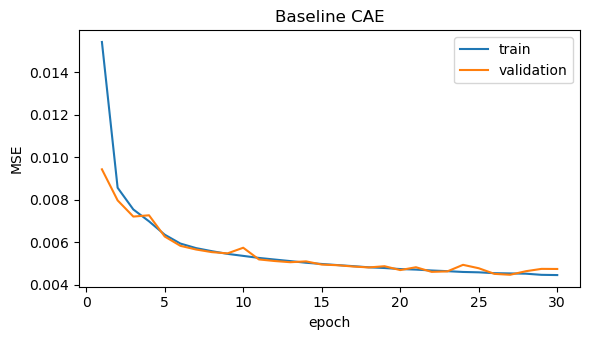

test MSE: 0.00449


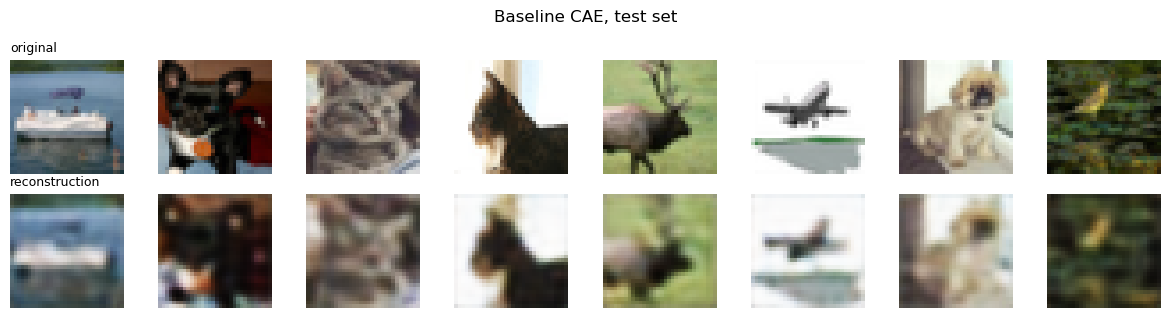

In [7]:
history = train_or_load("baseline 1024", baseline, train_loader, val_loader)
plot_history(history, "Baseline CAE")
print("test MSE:", round(evaluate(baseline, test_loader), 5))
show_images({"original": x_test, "reconstruction": predict(baseline, x_test[:8])}, title="Baseline CAE, test set")

The train and validation curves stay very close to each other, so the model doesn't overfit. This makes sense since it has only about 5000 parameters. Early stopping never stopped the training: the best validation epoch is 27 of 30, so with more epochs the model could still improve a little.

The test MSE (0.00449) is almost the same as the validation one (0.00447), so the result also holds on unseen images. From the reconstructions we can see that the model keeps the shapes and the main colours, but the images are blurry and small details are lost (as the antlers of the deer or the face of the dog).

## Other architectures
We try three types of autoencoder, each with a latent of 512, 1024 and 2048 values:

- **Wide**: the baseline autoencoder with more channels (32 and 64 instead of 8 and 12).
- **Number of stages**: 1 conv + pool stage (16x16 latent) or 3 stages (4x4 latent).
- **Two path**: two encoders in parallel, one with 3x3 filters and max pooling, one with 5x5 filters and stride 2, merged into one single latent.

All decoders mirror their encoders with upsample instead of pooling.

In [22]:
def conv_pool_encoder(channels, latent_ch, in_ch=3):
    """one conv + max pool per stage, then a conv to the latent channels"""
    layers = []
    for c in channels:
        layers += [nn.Conv2d(in_ch, c, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]
        in_ch = c
    layers += [nn.Conv2d(in_ch, latent_ch, 3, padding=1), nn.ReLU()]
    return nn.Sequential(*layers)


def upsample_decoder(channels, latent_ch):
    """mirror of the encoder: upsample + conv per stage, sigmoid at the end"""
    outs = list(reversed(channels))[:-1] + [3]   # e.g. (8, 12) -> (12, 3) like the baseline
    layers = []
    in_ch = latent_ch
    for c in outs:
        layers += [nn.Upsample(scale_factor=2), nn.Conv2d(in_ch, c, 3, padding=1), nn.ReLU()]
        in_ch = c
    layers[-1] = nn.Sigmoid()
    return nn.Sequential(*layers)


class TwoPathEncoder(nn.Module):
    def __init__(self, latent_ch, in_ch=3):
        super().__init__()
        # small 3x3 filters and max pool, keeps local detail
        self.small = nn.Sequential(
            nn.Conv2d(in_ch, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 16x16
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),      # 8x8
        )
        # bigger 5x5 filters with stride 2, sees more context
        self.big = nn.Sequential(
            nn.Conv2d(in_ch, 16, 5, stride=2, padding=2), nn.ReLU(),          # 16x16
            nn.Conv2d(16, 32, 5, stride=2, padding=2), nn.ReLU(),             # 8x8
        )
        self.merge = nn.Sequential(nn.Conv2d(64, latent_ch, 3, padding=1), nn.ReLU())

    def forward(self, x):
        return self.merge(torch.cat([self.small(x), self.big(x)], dim=1))


STAGES = {
    "baseline": (8, 12),
    "wide": (32, 64),
    "1 stage": (8,),
    "3 stages": (8, 12, 16),
}


def build(kind, latent_ch, in_ch=3):
    if kind == "two path":
        return AE(TwoPathEncoder(latent_ch, in_ch), upsample_decoder((16, 32), latent_ch))
    channels = STAGES[kind]
    return AE(conv_pool_encoder(channels, latent_ch, in_ch), upsample_decoder(channels, latent_ch))


# (type, latent channels), chosen so that every type gets a 512, a 1024 and a 2048 latent
EXPERIMENTS = [
    ("baseline", 16),                                         # 8x8x16 = 1024, already trained above
    ("wide", 8), ("wide", 16), ("wide", 32),                  # 8x8
    ("1 stage", 2), ("1 stage", 4), ("1 stage", 8),           # 16x16
    ("3 stages", 32), ("3 stages", 64), ("3 stages", 128),    # 4x4
    ("two path", 8), ("two path", 16), ("two path", 32),      # 8x8
]


Here we train (or load) every model of the list. After that, we show a table with latent size, number of parameters, validation and test MSE.

In [23]:
rows, models, histories = [], {}, {}
for kind, latent_ch in EXPERIMENTS:
    torch.manual_seed(SEED)
    model = build(kind, latent_ch)
    name = f"{kind} {latent_size(model)}"
    print("---", name)
    histories[name] = train_or_load(name, model, train_loader, val_loader)
    models[name] = model
    rows.append({
        "name": name,
        "type": kind,
        "latent channels": latent_ch,
        "latent size": latent_size(model),
        "params": count_params(model),
        "epochs": len(histories[name]["val"]),
        "val MSE": min(histories[name]["val"]),
        "test MSE": evaluate(model, test_loader),
    })

results = pd.DataFrame(rows).set_index("name")
results.style.format({"val MSE": "{:.5f}", "test MSE": "{:.5f}"})

--- baseline 1024
loaded results_report\baseline_1024.pt
--- wide 512
loaded results_report\wide_512.pt
--- wide 1024
loaded results_report\wide_1024.pt
--- wide 2048
loaded results_report\wide_2048.pt
--- 1 stage 512
loaded results_report\1_stage_512.pt
--- 1 stage 1024
loaded results_report\1_stage_1024.pt
--- 1 stage 2048
loaded results_report\1_stage_2048.pt
--- 3 stages 512
loaded results_report\3_stages_512.pt
--- 3 stages 1024
loaded results_report\3_stages_1024.pt
--- 3 stages 2048
loaded results_report\3_stages_2048.pt
--- two path 512
loaded results_report\two_path_512.pt
--- two path 1024
loaded results_report\two_path_1024.pt
--- two path 2048
loaded results_report\two_path_2048.pt


,type,latent channels,latent size,params,epochs,val MSE,test MSE
name,,,,,,,
baseline 1024,baseline,16,1024,4911,30,0.00447,0.00449
wide 512,wide,8,512,30411,30,0.00242,0.00243
wide 1024,wide,16,1024,39635,30,0.00183,0.00184
wide 2048,wide,32,2048,58083,30,0.00166,0.00167
1 stage 512,1 stage,2,512,427,30,0.00890,0.00880
1 stage 1024,1 stage,4,1024,627,30,0.00180,0.00183
1 stage 2048,1 stage,8,2048,1027,30,0.00170,0.00173
3 stages 512,3 stages,32,512,14175,30,0.00890,0.00893
3 stages 1024,3 stages,64,1024,23423,30,0.00838,0.00842


To make the interpretation easier we plot the test MSE against the latent size, per each type of autoencoder. 

Then we plot also the validation curves of all models and we compare their reconstructions on the same test images.

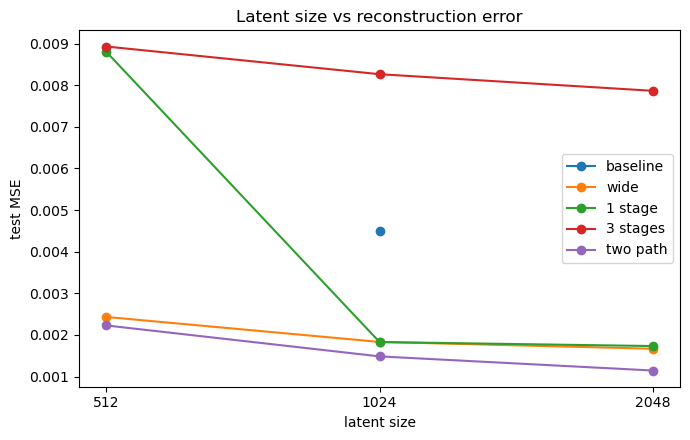

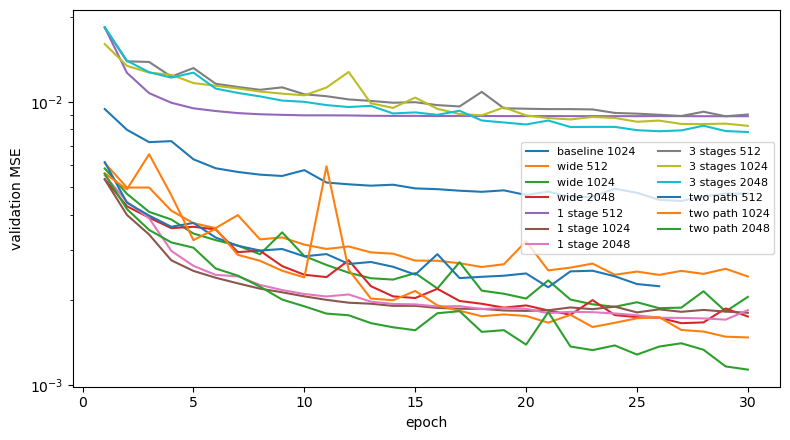

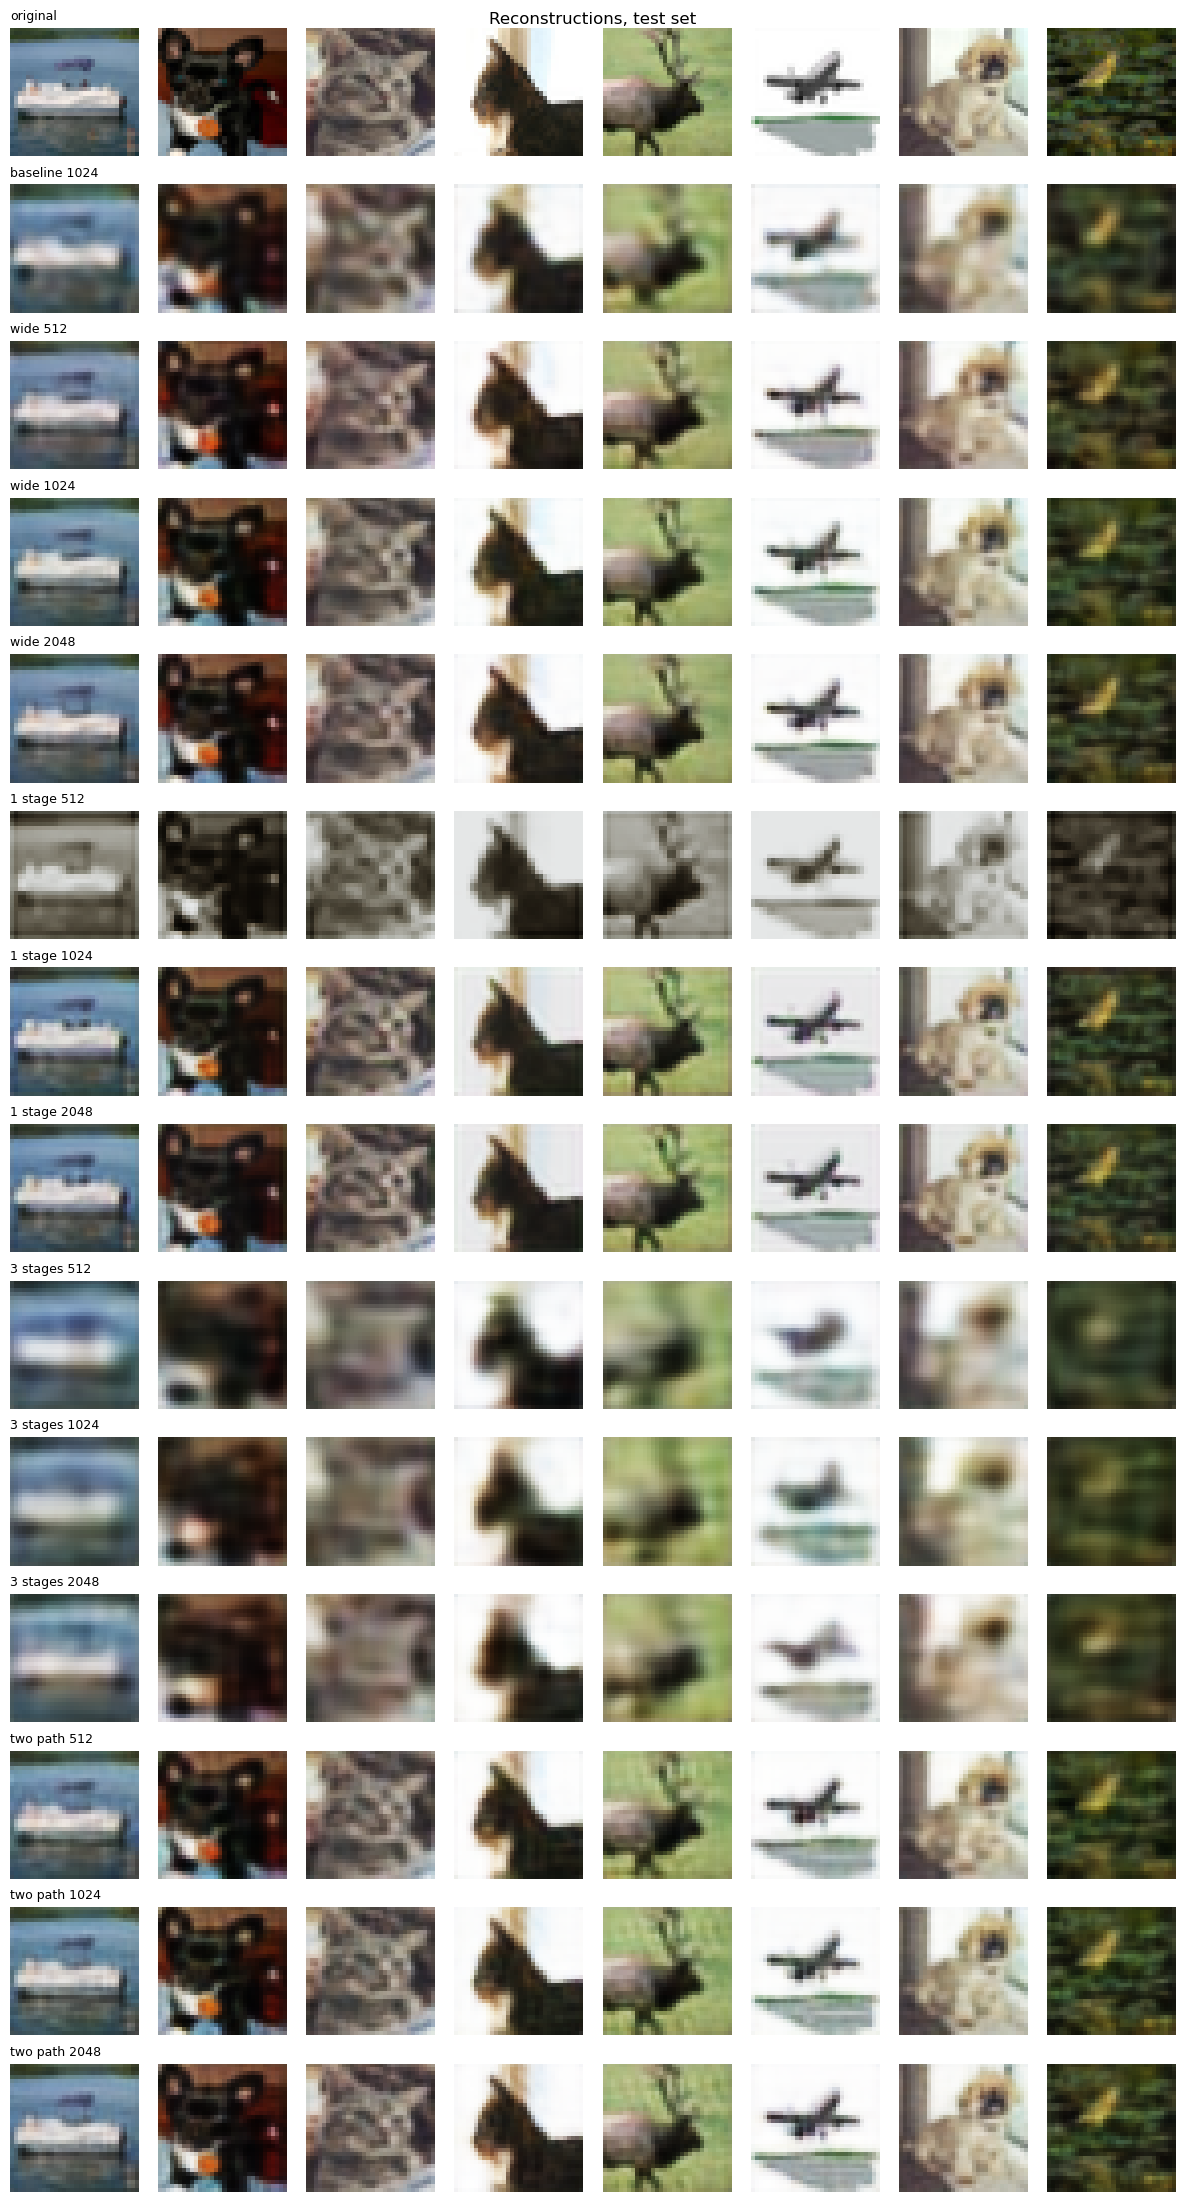

In [21]:
# latent size vs test error, one line per type
plt.figure(figsize=(7, 4.5))
for kind, df in results.groupby("type", sort=False):
    plt.plot(df["latent size"], df["test MSE"], "o-", label=kind)
plt.xscale("log", base=2)
plt.xticks([512, 1024, 2048], ["512", "1024", "2048"])
plt.xlabel("latent size")
plt.ylabel("test MSE")
plt.title("Latent size vs reconstruction error")
plt.legend()
plt.tight_layout()
plt.show()

# validation curves of all models
plt.figure(figsize=(8, 4.5))
for name, h in histories.items():
    plt.plot(range(1, len(h["val"]) + 1), h["val"], label=name)
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("validation MSE")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

show_images({"original": x_test[:8], **{name: predict(m, x_test[:8]) for name, m in models.items()}},
            title="Reconstructions, test set")

As we expect, for each type of autoencoder the error goes down when the latent gets bigger. A bigger latent space means less information lost.

But the latent size alone can't explain the results. For the same size different architectures get better results, and the two path encoder is the best at every size: already with a 1024 latent it beats all the other types.

We can see from the loss and the various reconstructions that, as we expected, the two path is the best architecture for this task. We think it's like this because the two kernels look at different details of the image and for the big number of parameters. The small 3x3 filters keep local details, while the bigger 5x5 filters see a larger part of the image and capture the context. The latent gets both kinds of information, so the decoder can rebuild better images.

At the same time also 1 stage and wide performed well with a big latent size, but 3 stages didn't. We think this is because the encoder halves the image three times, and every max pool keeps only 1 value out of 4. The latent ends up being only 4x4, so each of its 16 positions has to describe a block of 8x8 pixels and the information of the image is lost. Adding more channels can't bring it back, which is why the 3 stages reconstructions stay blurry even with 2048 values.

## Colourisation: grayscale -> RGB
Now the input is a 1-channel grayscale image ($0.299R + 0.587G + 0.114B$) and the target is the colour image. We start from the best RGB autoencoder (two path 2048) in two steps:
1. We **freeze its decoder**, which already turns a latent space into a colour image, and train only a new encoder that reads the gray image. This is done to force the new encoder learning the representation that works better until now.
2. We **unfreeze everything** and keep training the whole network, with a learning rate 10 times lower since the weights already start from a good point and we want just to refine the model.

As a reference we use the gray image copied into the three channels, a "colourisation" without any colour.
For this we compute the gray image from the coloured ones.

In [24]:
def to_gray(x):
    weights = torch.tensor([0.299, 0.587, 0.114]).view(1, 3, 1, 1)
    return (x * weights).sum(dim=1, keepdim=True)


g_train, g_val, g_test = to_gray(x_train), to_gray(x_val), to_gray(x_test)
gray_train_loader = make_loader(g_train, x_train, shuffle=True)
gray_val_loader = make_loader(g_val, x_val)
gray_test_loader = make_loader(g_test, x_test)

best_name = results["val MSE"].idxmin()
best_kind = results.loc[best_name, "type"]
best_latent = int(results.loc[best_name, "latent channels"])
print("best RGB autoencoder:", best_name)

best RGB autoencoder: two path 2048


loaded results_report\gray_frozen_decoder.pt


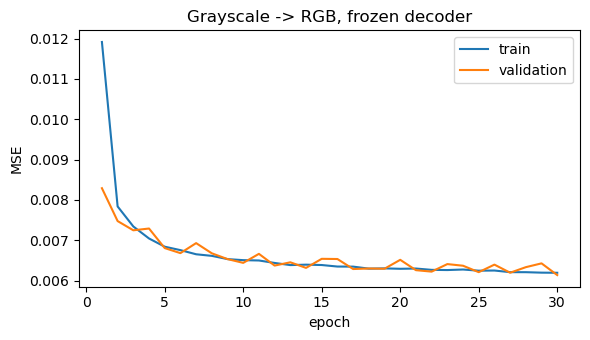

In [31]:
# step 1: new encoder for gray input, decoder of the best RGB model frozen
torch.manual_seed(SEED)
gray_model = build(best_kind, best_latent, in_ch=1)
gray_model.decoder = models[best_name].decoder
for p in gray_model.decoder.parameters():
    p.requires_grad = False

gray_history = train_or_load("gray frozen decoder", gray_model, gray_train_loader, gray_val_loader)
plot_history(gray_history, "Grayscale -> RGB, frozen decoder")

loaded results_report\gray_full_training.pt


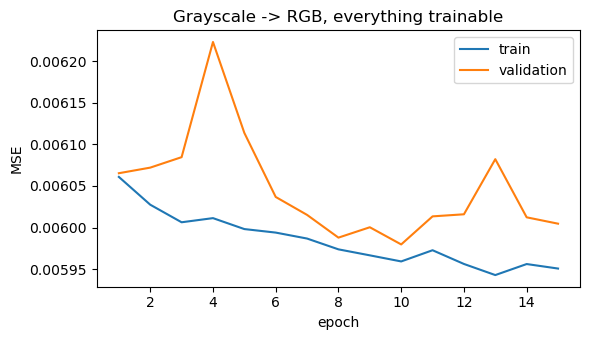

test MSE, gray copied:          0.00659
test MSE, frozen decoder:       0.00607
test MSE, everything trainable after freezing: 0.00592


In [38]:
# step 2: a copy of the model above with everything trainable
torch.manual_seed(SEED)
full_model = build(best_kind, best_latent, in_ch=1)
full_model.load_state_dict(gray_model.state_dict())

full_history = train_or_load("gray full training", full_model, gray_train_loader, gray_val_loader, lr=LR / 10)
plot_history(full_history, "Grayscale -> RGB, everything trainable")

print(f"test MSE, gray copied:          {loss_fn(g_test.repeat(1, 3, 1, 1), x_test).item():.5f}")
print(f"test MSE, frozen decoder:       {evaluate(gray_model, gray_test_loader):.5f}")
print(f"test MSE, everything trainable after freezing: {evaluate(full_model, gray_test_loader):.5f}")

We see from the plot and from test MSE that the finetuning helped the model to lower the MSE both on validation and training set. The result on MSE is still really similar to the copied gray image and for this we tried the approach that we can see down here in the notebook.

## Colourisation with luminance and chrominance
Here we predict only the colour of the image. In the YUV colour space the luminance $Y$ is exactly our gray image, while $U = 0.492\,(B - Y)$ and $V = 0.877\,(R - Y)$ hold the colour (the chrominance).

To do this we have to think again about how to train the network. It is trained in a grayscale -> UV examples in order to learn how to go from one to another. After that we transform the image again in RGB, we compute the loss and we see the transformed image.

With this idea the details come straight from the input, so the network only has to learn the colours. We use the same architecture as before, with 2 output channels and a tanh at the end, since U and V can be negative.

In [37]:
def rgb_to_uv(x):
    """chrominance U, V of an RGB image (the luminance Y is our gray image)"""
    r, g, b = x[:, 0:1], x[:, 1:2], x[:, 2:3]
    y = to_gray(x)
    return torch.cat([0.492 * (b - y), 0.877 * (r - y)], dim=1)


def yuv_to_rgb(y, uv):
    """put luminance and chrominance back together into an RGB image"""
    r = y + uv[:, 1:2] / 0.877
    b = y + uv[:, 0:1] / 0.492
    g = (y - 0.299 * r - 0.114 * b) / 0.587
    return torch.cat([r, g, b], dim=1)


uv_train, uv_val = rgb_to_uv(x_train), rgb_to_uv(x_val)
uv_train_loader = make_loader(g_train, uv_train, shuffle=True)
uv_val_loader = make_loader(g_val, uv_val)
uv_test_loader = make_loader(g_test, rgb_to_uv(x_test))

# going RGB -> YUV -> RGB should give back the same image
print("round trip error:", loss_fn(yuv_to_rgb(g_test, rgb_to_uv(x_test)), x_test).item())

round trip error: 6.094675753015772e-16


Here we see that the error in the reconstruction can be seen as the rounding error (<10^-15)

loaded results_report\gray_to_uv.pt


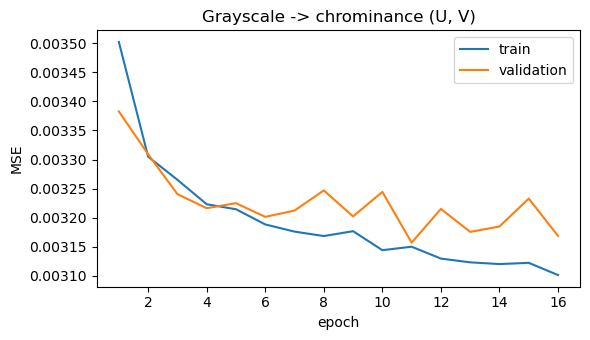

test MSE, gray -> UV: 0.00310


In [43]:
torch.manual_seed(SEED)
uv_model = build(best_kind, best_latent, in_ch=1)
uv_model.decoder[-2] = nn.Conv2d(uv_model.decoder[-2].in_channels, 2, 3, padding=1)
uv_model.decoder[-1] = nn.Tanh()

uv_history = train_or_load("gray to uv", uv_model, uv_train_loader, uv_val_loader)
plot_history(uv_history, "Grayscale -> chrominance (U, V)")
print(f"test MSE, gray -> UV: {evaluate(uv_model, uv_test_loader):.5f}")


The results on the test loss are comparable to the validation loss. This loss is not the total colorisation loss. To add it we have to compute the transformation YUV -> RGB.

## Colourisation results
We compare all the approaches on the test set, first with the MSE in RGB and then on the same images.

gray copied                   test MSE 0.00659
frozen decoder + fine tuning  test MSE 0.00592
U, V + real gray              test MSE 0.00516


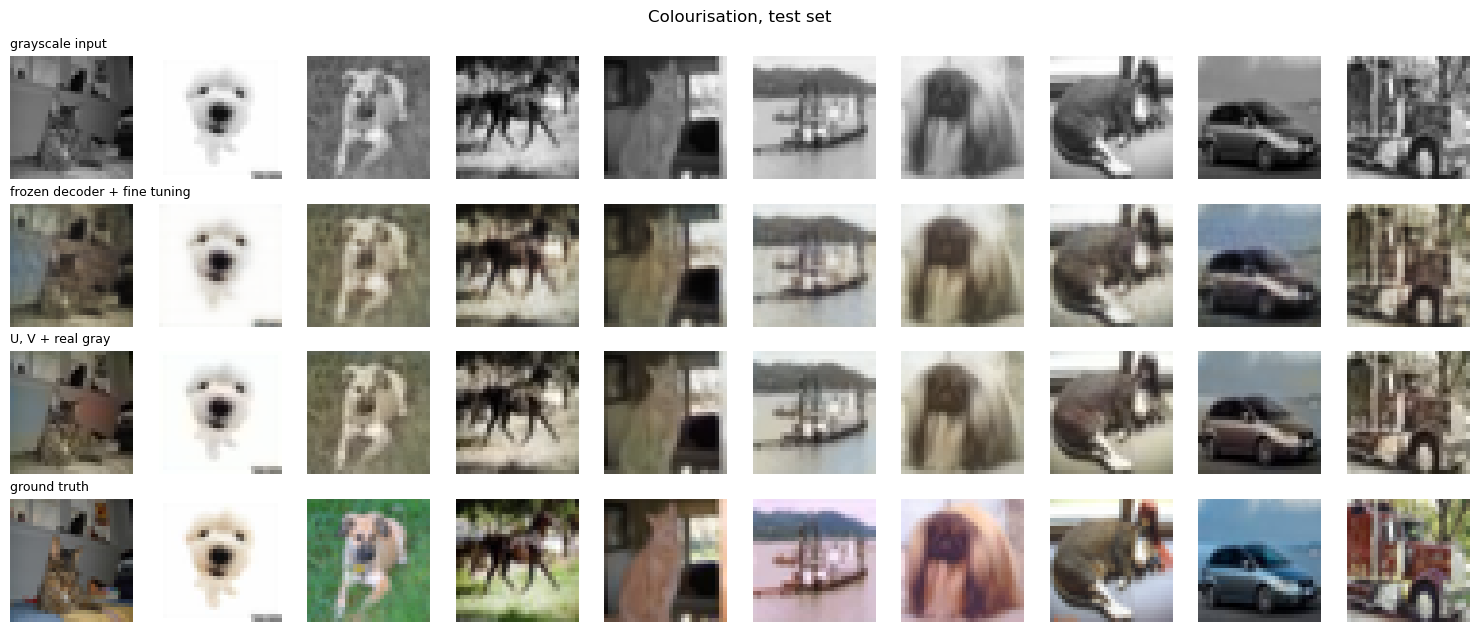

In [46]:
predictions = {
    "gray copied                  ":                      g_test.repeat(1, 3, 1, 1),
    "frozen decoder + fine tuning ":     predict(full_model, g_test),
    "U, V + real gray             ":                 yuv_to_rgb(g_test, predict(uv_model, g_test)).clamp(0, 1),
}
for name, pred in predictions.items():
    print(f"{name:<22} test MSE {loss_fn(pred, x_test).item():.5f}")

idx = torch.arange(16, 26)
show_images({"grayscale input": g_test[idx], **{name: p[idx] for name, p in list(predictions.items())[1:]},
             "ground truth": x_test[idx]}, n=10, title="Colourisation, test set")

Both the models beat the gray copy (0.00659), so they learned some colour. However the colours stay pale and brownish. We think that this happens because the MSE loss, when the network isn't sure about the colour of an object (a car can be red, blue or white) it predicts the average to avoid big MSE. For this the found color looks a bit brown.

The idea of freezing the decoder to force the network to learn the representation worked better than the gray copy (0.00592) but predicting only U and V gives the lowest error (0.00516). Since the details come from the gray input, these images are as sharp as the input, while the other models blur them like the autoencoder reconstructions.

## Colourisation on bigger images
CIFAR-10 images are only 32x32, so it is hard to judge the colours we predict. Here we check if the same idea works on real photos. We take a random sample of 10,000 images from the validation set of [Places365](http://places2.csail.mit.edu/), photos of scenes (beaches, forests, streets, kitchens...) at 256x256, and resize them to 96x96. We split them 80 / 10 / 10 like CIFAR-10.

In [ ]:
N_PLACES = 10000
SIZE = 96

places = torchvision.datasets.Places365(root="./data", split="val", small=True, download=True)
to_small = torchvision.transforms.Compose([torchvision.transforms.Resize(SIZE), torchvision.transforms.ToTensor()])

# random sample, same seed as the rest of the notebook
pick = torch.randperm(len(places), generator=torch.Generator().manual_seed(SEED))[:N_PLACES]
p = torch.stack([to_small(places[i][0]) for i in pick.tolist()])

n_p_train, n_p_val = int(0.8 * len(p)), int(0.1 * len(p))
p_train, p_val, p_test = p[:n_p_train], p[n_p_train:n_p_train + n_p_val], p[n_p_train + n_p_val:]
print("train", tuple(p_train.shape), "| val", tuple(p_val.shape), "| test", tuple(p_test.shape))

train (8000, 3, 96, 96) | val (1000, 3, 96, 96) | test (1000, 3, 96, 96)


We train the same gray -> UV model as before, from scratch, on these photos. The network only has convolutions, pooling and upsampling, so it works on 96x96 images without any change.

epoch  1  train 0.00413  val 0.00385


epoch  2  train 0.00392  val 0.00386


epoch  3  train 0.00387  val 0.00371


epoch  4  train 0.00380  val 0.00373


epoch  5  train 0.00378  val 0.00392


epoch  6  train 0.00379  val 0.00371


... (18 outputs left out)

epoch 25  train 0.00363  val 0.00362


epoch 26  train 0.00365  val 0.00362


epoch 27  train 0.00363  val 0.00367


epoch 28  train 0.00364  val 0.00361
early stopping


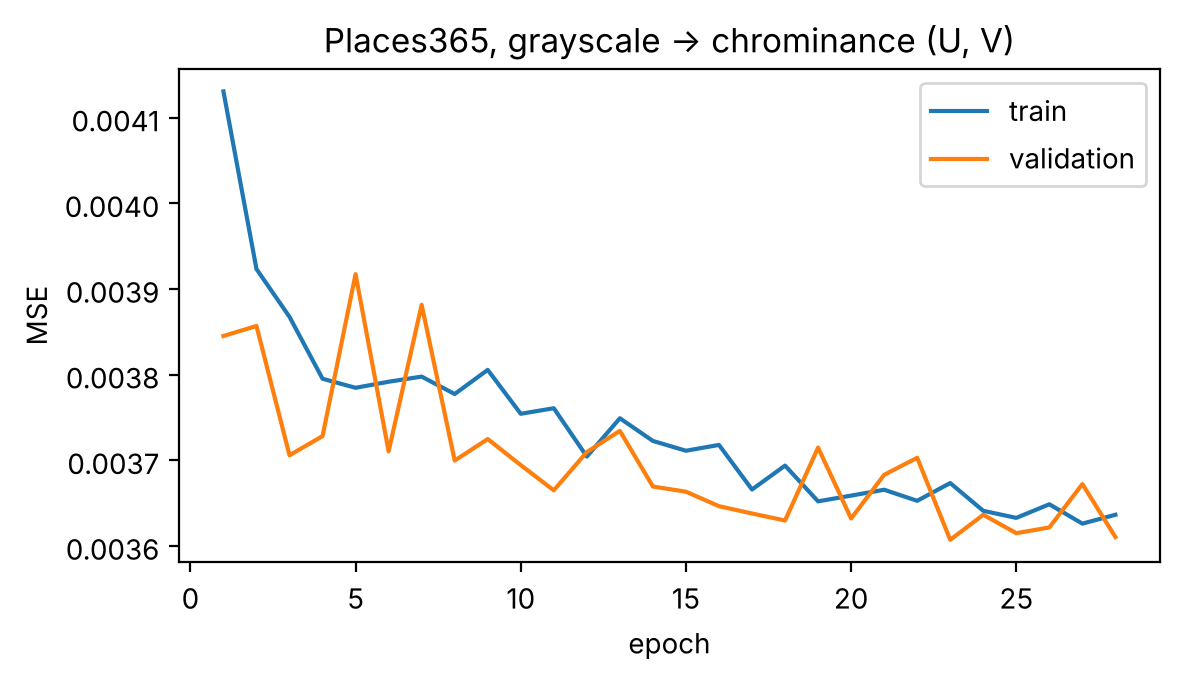

In [ ]:
pg_train, pg_val, pg_test = to_gray(p_train), to_gray(p_val), to_gray(p_test)
places_train_loader = make_loader(pg_train, rgb_to_uv(p_train), shuffle=True)
places_val_loader = make_loader(pg_val, rgb_to_uv(p_val))

torch.manual_seed(SEED)
places_model = build(best_kind, best_latent, in_ch=1)
places_model.decoder[-2] = nn.Conv2d(places_model.decoder[-2].in_channels, 2, 3, padding=1)
places_model.decoder[-1] = nn.Tanh()

places_history = train_or_load("places gray to uv", places_model, places_train_loader, places_val_loader)
plot_history(places_history, "Places365, grayscale -> chrominance (U, V)")

gray copied       test MSE 0.00730
U, V + real gray  test MSE 0.00610


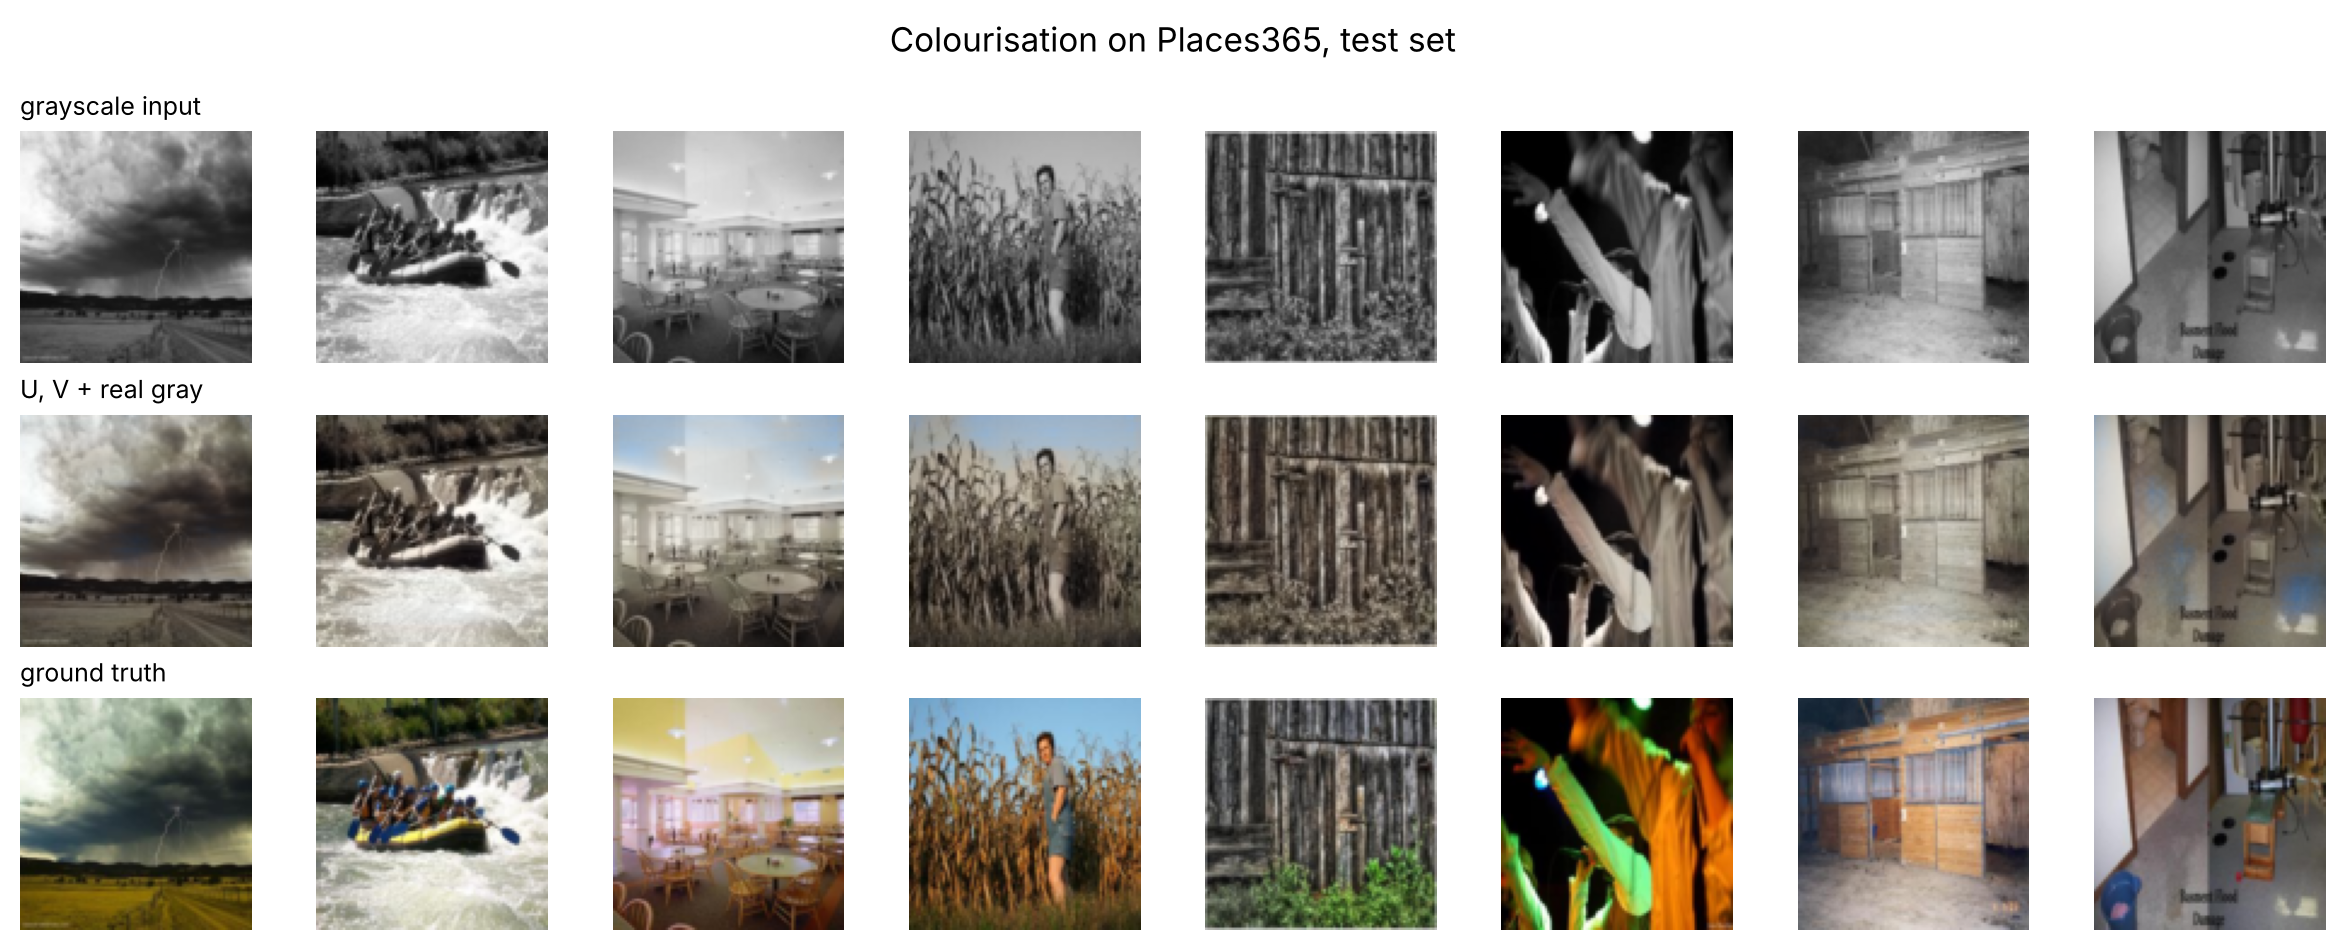

In [ ]:
places_pred = yuv_to_rgb(pg_test, predict(places_model, pg_test)).clamp(0, 1)
print(f"gray copied       test MSE {loss_fn(pg_test.repeat(1, 3, 1, 1), p_test).item():.5f}")
print(f"U, V + real gray  test MSE {loss_fn(places_pred, p_test).item():.5f}")

idx = torch.arange(8)
show_images({"grayscale input": pg_test[idx], "U, V + real gray": places_pred[idx], "ground truth": p_test[idx]},
            n=8, title="Colourisation on Places365, test set")

The model beats the gray copy here too, and with 96x96 photos we can finally see what it learned. It paints the top of outdoor photos light blue, since that is usually sky, and it gives warm brown tones to wood and ground. But the colours stay pale, close to sepia, and the bright ones (the yellow raft, the orange clothes) are lost. It is the same problem as on CIFAR-10: with the MSE loss the network predicts the average colour when it is not sure. More images, a bigger network, or a loss that lets the model pick one colour among many, like the classification over colour bins of Zhang et al. (2016), should help.

## Conclusion
We built a convolutional autoencoder in PyTorch to reconstruct CIFAR-10 images and then to colourise grayscale ones.

The baseline from the assignment already keeps the shapes and the main colours of the images, but its reconstructions are blurry probably because the small details get lost in the bottleneck. Our experiments showed that a bigger latent space helps, but how the network is built matters just as much. Keeping a high spatial resolution in the latent is more useful than adding channels, a wider network learns a much better encoding with the same latent, and looking at the image with both small and big filters, as the two path encoder does, gives the sharpest reconstructions.

Colourisation turned out to be much harder than reconstruction. Reusing the decoder of the best autoencoder gives images with some colour, but they stay a bit blurry and pale. Predicting only the chrominance and combining it with the real gray image solves in part the blur, since the details come straight from the input, but the colours are still washed out. The reason is the MSE loss: when the network isn't sure about the colour of an object, it chooses the average one to avoid big losses.

We see three ways to improve the colourisation:
- Predict a distribution over colour bins for every pixel (a classification, as in Zhang et al. 2016) instead of one colour with MSE, so the network can pick one vivid colour instead of the average.
- Give the network global information, like the class of the image, so it knows that a frog is green and the sky is blue.
- Train on more and bigger images with a bigger network, and add skip connections so the details don't have to pass through the bottleneck.